# 第 9 堂：線性迴歸（Linear Regression）
LESSON 09 · LINEAR REGRESSION

### 本堂學習目標
學完後，你應該能夠：
1. 說出線性迴歸在做什麼：**找一條最適合資料的直線**。
2. 看懂直線公式 `y = a × x + b`，知道斜率 a 和截距 b 的意思。
3. 用 `coef_` 和 `intercept_` 取出模型學到的斜率和截距，並用白話解釋。
4. 自己用公式算出預測值，確認和 `predict()` 一樣。
5. 把模型學到的直線畫在散佈圖上。
6. 理解「誤差（殘差）」和模型怎麼挑出最好的那條線。
7. 解讀多個特徵的線性迴歸，並知道異常值和「外推」的風險。

### 本堂上課順序
| 順序 | 內容 |
| :--- | :--- |
| 1. 生活例子 | 計程車車資怎麼算？ |
| 2. 概念解說 | 直線公式、斜率、截距、誤差 |
| 3. 程式教學 | 計程車 → 畫線 → 誤差 → 房價（兩個特徵） → 異常值 |
| 4. 逐行解析 | 每段程式後面都有解析表 |
| 5. 實際練習 | 4 個練習，附參考解答 |
| 6. 小考驗收 | 自我檢查，再回對話做小考 |

---
## 一、生活例子：計程車車資怎麼算？

台灣的計程車大致是這樣收費（簡化版）：
- **一上車**就要付起跳價：**85 元**
- 之後**每多 1 公里**，多付 **25 元**

所以：

| 公里 | 車資 |
| :--- | :--- |
| 0 | 85 |
| 1 | 85 + 25 = 110 |
| 2 | 85 + 50 = 135 |
| 10 | 85 + 250 = 335 |

寫成公式就是：

> **車資 = 25 × 公里 + 85**

畫成圖會是一條**直線**。

### 換個角度想
假設你**不知道**計程車的收費規則，手上只有 12 張搭車收據（每張寫著公里和車資）。
因為塞車、等紅燈，每張收據都和公式有一點點出入。

你能不能從這 12 張收據，**反推**出「起跳價大約多少」、「每公里大約多少錢」？

**這就是線性迴歸在做的事：** 從資料中，找出一條最能代表它們的直線。
第 8 堂我們直接用了 `LinearRegression`，今天要打開它，看看它到底學到了什麼。

---
## 二、概念解說

### 1. 直線公式：y = a × x + b

| 符號 | 名稱 | 計程車例子 | 意思 |
| :--- | :--- | :--- | :--- |
| `x` | 特徵（輸入） | 公里 | 我們給模型的條件 |
| `y` | 標籤（輸出） | 車資 | 要預測的答案 |
| `a` | **斜率**（Slope）／係數（Coefficient） | 25 | **x 每增加 1，y 會增加多少** |
| `b` | **截距**（Intercept） | 85 | **x 等於 0 時，y 是多少**（直線和 Y 軸交叉的地方） |

斜率的白話：
- a 是**正數** → x 越大，y 越大（往右上的線）
- a 是**負數** → x 越大，y 越小（往右下的線）
- a 越大（不管正負）→ 線越陡，x 對 y 的影響越大

### 2. 模型「學」的到底是什麼？
**線性迴歸模型學的，就只有 a 和 b 這兩個數字。**

| 動作 | 意思 |
| :--- | :--- |
| `fit()` | 從資料中找出最適合的 a 和 b |
| `predict()` | 把新的 x 代進 `a × x + b`，算出 y |

第 2 堂預測 60 坪房子是 1500 萬，其實就是 `25 × 60 + 0 = 1500`。

### 3. 什麼叫「最適合」的直線？誤差（殘差）
資料點不會剛好都在直線上。每一個點和直線的**上下距離**，叫做**誤差**，也叫**殘差**（Residual）：

> **殘差 = 實際值 − 預測值**

- 殘差是正的 → 點在線的**上面**（模型猜太低）
- 殘差是負的 → 點在線的**下面**（模型猜太高）

模型挑選直線的規則叫做**最小平方法**（Least Squares）：
1. 算出每一個點的殘差
2. 每個殘差都**平方**（讓負號消失，而且差越多的點會被懲罰得越重）
3. 把所有平方加起來
4. **讓這個總和最小的那條線，就是答案**

不用背公式，等一下會用程式親眼看到：模型找到的線，誤差總和真的比隨便畫的線小很多。

### 4. 多個特徵怎麼辦？
第 8 堂用了坪數和屋齡兩個特徵，公式就變成：

> **房價 = a₁ × 坪數 + a₂ × 屋齡 + b**

每個特徵都有自己的斜率。`a₁` 的意思是：**在屋齡不變的情況下**，坪數每多 1，房價多多少。

---
## 三、程式教學

### 步驟 0：匯入工具與中文字型設定

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 中文字型設定（同第 7、8 堂）
import sys, os
import matplotlib.font_manager as fm
if "google.colab" in sys.modules:
    os.system("apt-get -qq install -y fonts-noto-cjk > /dev/null")
noto = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if os.path.exists(noto):
    fm.fontManager.addfont(noto)
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "Microsoft JhengHei", "PingFang TC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("準備完成")

準備完成


### 步驟 1：12 張計程車收據，先畫圖看看

      公里   車資
0    1.5  147
1    2.0  104
2    3.0  165
3    3.5  166
4    5.0  205
5    6.0  232
6    7.5  248
7    8.0  282
8   10.0  325
9   12.0  425
10  15.0  463
11  18.0  531


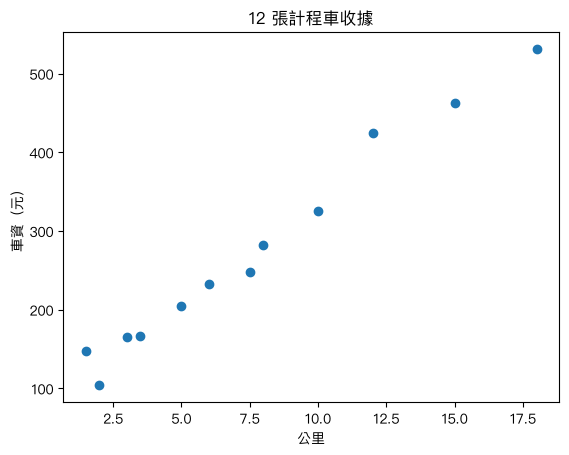

In [2]:
taxi = pd.DataFrame({
    "公里": [1.5, 2, 3, 3.5, 5, 6, 7.5, 8, 10, 12, 15, 18],
    "車資": [147, 104, 165, 166, 205, 232, 248, 282, 325, 425, 463, 531]
})
print(taxi)

plt.scatter(taxi["公里"], taxi["車資"])
plt.title("12 張計程車收據")
plt.xlabel("公里")
plt.ylabel("車資（元）")
plt.show()

#### 觀察
點大致排成一條往右上的直線 → 公里和車資有明顯的正相關，很適合用線性迴歸。
（第 7 堂：**先看圖，再建模型**。）

### 步驟 2：訓練模型，打開看看它學到什麼

In [3]:
X = taxi[["公里"]]     # 特徵：兩層中括號，二維
y = taxi["車資"]       # 標籤：一層中括號，一維

model = LinearRegression()
model.fit(X, y)

print("斜率 a（coef_）：", model.coef_)
print("截距 b（intercept_）：", model.intercept_)

斜率 a（coef_）： [25.59136691]
截距 b（intercept_）： 79.28249400479618


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `model.fit(X, y)` | 從 12 張收據中找出最適合的 a 和 b |
| `model.coef_` | **斜率**（coefficient 係數）。是一個陣列，因為可能有好幾個特徵，每個特徵一個斜率 |
| `model.intercept_` | **截距**，只有一個數字 |

注意名字**後面有一個底線 `_`**。sklearn 的慣例是：**訓練之後才會產生的東西，名字後面加底線。** 沒有 `fit()` 之前，模型裡面沒有 `coef_`，直接取會出錯。

#### 白話解讀
- 斜率約 **25.6** → 每多 1 公里，車資大約多 **25.6 元**（真實規則是 25）
- 截距約 **79.3** → 0 公里時大約 **79 元**，也就是「起跳價」（真實規則是 85）

模型**從來沒有被告知**收費規則，只看了 12 張有誤差的收據，就推算出很接近的答案。這就是「從資料中學習規律」（第 1 堂）。

為什麼不是剛好 25 和 85？因為收據有塞車、等紅燈造成的誤差，而且只有 12 張。資料越多、誤差越小，就會越接近真實規則。

### 步驟 3：自己用公式算，和 predict() 比比看

In [4]:
a = model.coef_[0]        # 取出陣列裡的第一個（也是唯一一個）斜率
b = model.intercept_

# 自己用公式算 10 公里的車資
my_answer = a * 10 + b
print("自己算：", round(my_answer, 2))

# 用 predict 算
model_answer = model.predict(pd.DataFrame({"公里": [10]}))
print("predict：", model_answer.round(2))

自己算： 335.2
predict： [335.2]


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `model.coef_[0]` | `coef_` 是陣列，用 `[0]` 取出第一個數字（Python 從 0 開始數，跟 Pandas 的索引一樣） |
| `a * 10 + b` | 自己把 10 公里代入公式 `y = a × x + b` |
| `model.predict(...)` | 讓模型預測 10 公里 |

兩個答案**完全一樣**！這證明了：

> **`predict()` 沒有什麼魔法，它就是把 x 代進 `a × x + b`。**

#### 複習：predict 和 score 的差別（第 8 堂加強練習第 7 題）
| 寫法 | 給什麼 | 得到什麼 | 比喻 |
| :--- | :--- | :--- | :--- |
| `model.predict(X_test)` | 只有題目 | **每一題的答案**（一串預測值，例如 335） | 學生在考卷上**寫答案** |
| `model.score(X_test, y_test)` | 題目 + 正確答案 | **一個分數**（例如 0.98） | 老師**改考卷打分數** |

判斷方法：題目問「作答」或「預測多少」→ `predict`；問「準不準」「幾分」→ `score`。

### 步驟 4：把直線畫在散佈圖上

**畫一條直線只需要兩個點。** 我們讓模型預測 0 公里和 20 公里，再用 `plt.plot` 把這兩點連起來。

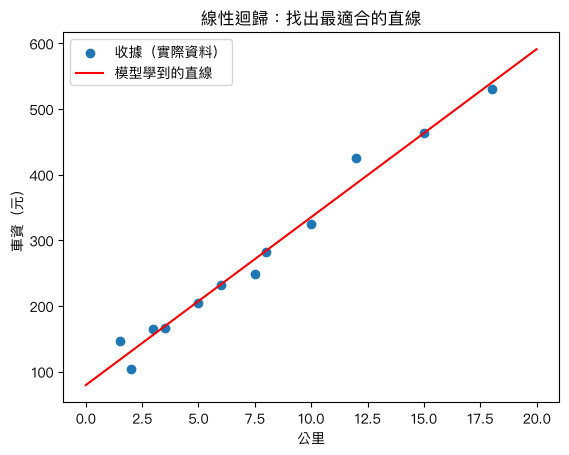

In [5]:
line_x = pd.DataFrame({"公里": [0, 20]})
line_y = model.predict(line_x)

plt.scatter(taxi["公里"], taxi["車資"], label="收據（實際資料）")
plt.plot(line_x["公里"], line_y, color="red", label="模型學到的直線")
plt.title("線性迴歸：找出最適合的直線")
plt.xlabel("公里")
plt.ylabel("車資（元）")
plt.legend()
plt.show()

#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `pd.DataFrame({"公里": [0, 20]})` | 準備兩個 x：0 和 20（直線的兩端） |
| `model.predict(line_x)` | 算出這兩點的 y |
| `plt.scatter(...)` | 畫原本的資料點（第 7 堂） |
| `plt.plot(..., color="red")` | 把兩點連成紅色直線（第 7 堂折線圖只有兩個點，就是一條直線） |
| `label` + `plt.legend()` | 圖例（第 7 堂） |

#### 觀察
- 紅線穿過點群的中間，有些點在線上面、有些在線下面。
- 紅線在 x = 0 的地方和 Y 軸交叉，交叉的高度就是**截距**（約 79）。
- 紅線往右每走 1 格（1 公里），就往上升約 25.6，這就是**斜率**。

### 步驟 5：誤差（殘差）—— 模型怎麼挑出這條線？

In [6]:
taxi["預測車資"] = model.predict(X).round(1)
taxi["殘差"] = (taxi["車資"] - taxi["預測車資"]).round(1)
print(taxi)

      公里   車資   預測車資    殘差
0    1.5  147  117.7  29.3
1    2.0  104  130.5 -26.5
2    3.0  165  156.1   8.9
3    3.5  166  168.9  -2.9
4    5.0  205  207.2  -2.2
5    6.0  232  232.8  -0.8
6    7.5  248  271.2 -23.2
7    8.0  282  284.0  -2.0
8   10.0  325  335.2 -10.2
9   12.0  425  386.4  38.6
10  15.0  463  463.2  -0.2
11  18.0  531  539.9  -8.9


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `model.predict(X)` | 對 12 張收據都做預測 |
| `taxi["殘差"] = 車資 − 預測車資` | 實際 − 預測：正數代表點在線上面，負數代表點在線下面 |

畫出來看更清楚（灰色虛線就是每個點的殘差）：

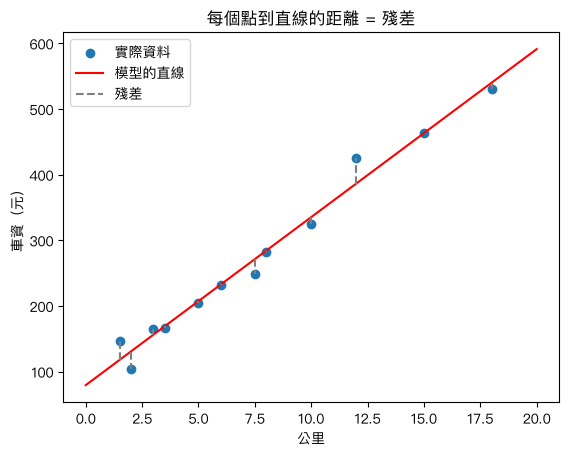

In [7]:
plt.scatter(taxi["公里"], taxi["車資"], label="實際資料")
plt.plot(line_x["公里"], line_y, color="red", label="模型的直線")
plt.vlines(taxi["公里"], taxi["預測車資"], taxi["車資"], colors="gray", linestyles="--", label="殘差")
plt.title("每個點到直線的距離 = 殘差")
plt.xlabel("公里")
plt.ylabel("車資（元）")
plt.legend()
plt.show()

#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `plt.vlines(x, 下端, 上端)` | **新指令**：畫垂直線（v = vertical）。在每個 x 位置，從預測值畫到實際值 |
| `linestyles="--"` | 虛線（第 7 堂學過的是 `linestyle`，`vlines` 的參數名多一個 s） |

`vlines` 只是為了這張說明圖，不用特別背。

#### 實驗：模型的線 vs 隨便畫的線
假設有人憑感覺說：「應該是每公里 20 元、起跳 100 元吧？」
我們來比較兩條線的**殘差平方和**（最小平方法要讓它最小）。

In [8]:
# 模型的線
model_error = (taxi["殘差"] ** 2).sum()

# 隨便畫的線：車資 = 20 × 公里 + 100
guess = 20 * taxi["公里"] + 100
guess_error = ((taxi["車資"] - guess) ** 2).sum()

print("模型的線，殘差平方和：", round(model_error))
print("隨便畫的線，殘差平方和：", round(guess_error))

模型的線，殘差平方和： 3869
隨便畫的線，殘差平方和： 19143


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `taxi["殘差"] ** 2` | `**` 是次方，`** 2` 就是平方。每個殘差都平方 |
| `.sum()` | 全部加起來 |
| `20 * taxi["公里"] + 100` | 用猜的公式算出每張收據的「猜測車資」，Pandas 會自動對每一列計算 |

#### 結果
隨便畫的線，誤差大約是模型的 **5 倍**。

sklearn 的 `fit()` 會用數學方法，直接找出「殘差平方和**最小**」的那一組 a 和 b，所以不管你怎麼猜，都不會比模型的線更小。這就是「最適合的直線」的意思。

**為什麼要平方，不直接加起來？**
殘差有正有負，直接加起來會互相抵銷（+50 和 −50 加起來變 0，好像沒誤差）。平方之後全部變正數，而且差 50 的點（平方 2500）會比差 10 的點（平方 100）被懲罰得重很多，模型就會努力避免離某個點太遠。
（第 8 堂算平均誤差時用 `abs()` 取絕對值，也是為了消除負號。）

### 步驟 6：兩個特徵的線性迴歸 —— 回到房價

用第 8 堂的房屋資料（已經清理好的版本），看看模型對**坪數**和**屋齡**分別學到什麼。

In [9]:
house = pd.DataFrame({
    "坪數": [43, 26, 59, 58, 17, 23, 24, 23, 41, 31, 37, 25, 58, 45, 45, 20, 22, 56, 29, 54,
             51, 15, 36, 39, 36, 19, 48, 26, 31, 34, 28, 35, 53, 36, 49, 57, 25, 26, 40, 23],
    "屋齡": [28, 27, 28, 38, 17, 37, 40, 36, 13, 3, 35, 38, 14, 26, 7, 35, 34, 17, 32, 9,
             39, 32, 33, 27, 2, 32, 29, 9, 35, 6, 16, 31, 31, 1, 11, 38, 23, 6, 14, 25],
    "房價": [1069, 608, 1494, 1340, 516, 507, 462, 400, 1105, 976, 828, 541, 1582, 1093, 1324, 493, 527, 1516, 718, 1579,
             1171, 319, 863, 918, 1014, 379, 1185, 799, 626, 917, 758, 819, 1275, 1122, 1392, 1331, 669, 753, 1035, 586]
})

X = house[["坪數", "屋齡"]]
y = house["房價"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

house_model = LinearRegression()
house_model.fit(X_train, y_train)

print("斜率 coef_：", house_model.coef_.round(2))
print("截距 intercept_：", round(house_model.intercept_, 2))
print("測試集分數：", round(house_model.score(X_test, y_test), 3))

斜率 coef_： [25.93 -8.02]
截距 intercept_： 162.64
測試集分數： 0.982


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `X = house[["坪數", "屋齡"]]` | 兩個特徵，二維 (40, 2) |
| `train_test_split(...)` | 第 8 堂：切出 20% 當考卷 |
| `house_model.coef_` | 這次有**兩個**斜率，順序和 X 的欄位順序一樣：第一個是坪數、第二個是屋齡 |
| `house_model.score(X_test, y_test)` | 第 8 堂：用考卷打分數 |

#### 白話解讀
模型學到的公式大約是：

> **房價 ≈ 25.9 × 坪數 − 8.0 × 屋齡 + 162.6**

| 係數 | 數值 | 白話意思 |
| :--- | :--- | :--- |
| 坪數的斜率 | 約 **+25.9** | **屋齡相同時**，每多 1 坪，房價多約 26 萬 |
| 屋齡的斜率 | 約 **−8.0** | **坪數相同時**，每老 1 年，房價少約 8 萬（負號 = 越老越便宜） |
| 截距 | 約 162.6 | 公式裡的基本值（等一下會說明為什麼不能直接解讀） |

「**○○相同時**」這幾個字很重要：多特徵時，每個斜率都是在「其他特徵固定不動」的情況下，這個特徵單獨的影響。

**這就是線性迴歸最大的優點：可以解釋。** 你可以跟主管說「每多 1 坪大約多 26 萬，每老 1 年大約少 8 萬」，而不是只丟一個預測數字。
第 17 堂的深度學習預測能力很強，但很難說清楚它為什麼這樣預測。

### 步驟 7：注意一 —— 異常值會把直線拉歪

回到計程車。如果有一張收據**打錯了**：4 公里卻寫成 900 元（第 6 堂的異常值），會發生什麼事？

正常資料 → 斜率： [25.6] 截距： 79.3
多一個異常值 → 斜率： [18.] 截距： 190.4


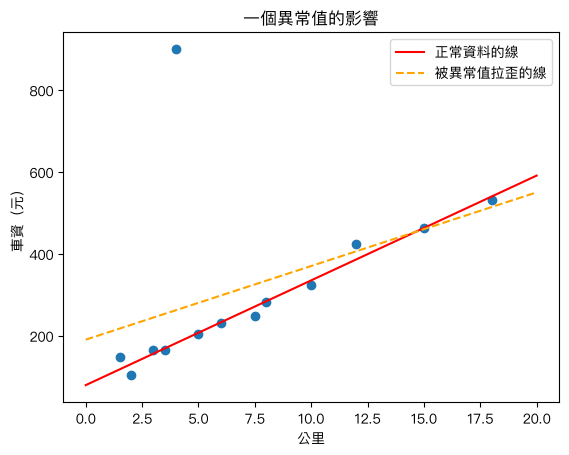

In [10]:
taxi_bad = pd.concat([
    taxi[["公里", "車資"]],
    pd.DataFrame({"公里": [4], "車資": [900]})
], ignore_index=True)

bad_model = LinearRegression()
bad_model.fit(taxi_bad[["公里"]], taxi_bad["車資"])

print("正常資料 → 斜率：", model.coef_.round(1), "截距：", round(model.intercept_, 1))
print("多一個異常值 → 斜率：", bad_model.coef_.round(1), "截距：", round(bad_model.intercept_, 1))

plt.scatter(taxi_bad["公里"], taxi_bad["車資"])
plt.plot(line_x["公里"], model.predict(line_x), color="red", label="正常資料的線")
plt.plot(line_x["公里"], bad_model.predict(line_x), color="orange", linestyle="--", label="被異常值拉歪的線")
plt.title("一個異常值的影響")
plt.xlabel("公里")
plt.ylabel("車資（元）")
plt.legend()
plt.show()

#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `pd.concat([表1, 表2], ignore_index=True)` | **新指令**：把兩張表上下接起來。`ignore_index=True` 讓索引重新從 0 編號 |
| `pd.DataFrame({"公里": [4], "車資": [900]})` | 一張打錯的收據 |

#### 結果
**只多了 1 張**錯的收據（13 張裡的 1 張），斜率就從約 25.6 掉到約 18，截距從約 79 跳到約 190。
橘色的線被那個點往上拉，結果短程預測太貴、長程預測太便宜，**兩邊都不準了**。

原因就是步驟 5 的「平方」：900 這個點的殘差非常大，平方之後更大，模型為了讓總和變小，只好把整條線往它那邊拉。

> 這就是為什麼第 6 堂要學異常值、第 7 堂要先畫圖：**線性迴歸對異常值非常敏感。**

### 步驟 8：注意二 —— 不要「外推」太遠

模型只看過特定範圍的資料。超出這個範圍去預測，叫做**外推**（Extrapolation），結果常常不可靠。

In [ ]:
print("房屋資料的坪數範圍：", house["坪數"].min(), "～", house["坪數"].max())

test_houses = pd.DataFrame({"坪數": [30, 0, 300], "屋齡": [10, 10, 10]})
test_houses["預測房價"] = house_model.predict(test_houses).round(0)
print(test_houses)

房屋資料的坪數範圍： 15 ～ 59
    坪數  屋齡    預測房價
0   30  10   860.0
1    0  10    82.0
2  300  10  7862.0


#### 逐行解析與觀察

| 程式碼 | 意思 |
| :--- | :--- |
| `house["坪數"].min()`、`.max()` | 最小值、最大值（第 5 堂 `describe()` 裡的 min 和 max） |

| 坪數 | 合理嗎？ | 原因 |
| :--- | :--- | :--- |
| 30 | ✓ 合理 | 在 15～59 坪的範圍內 |
| 0 | ✗ 不合理 | 0 坪的房子根本不存在，但模型還是算出 82 萬 |
| 300 | ✗ 不可靠 | 模型沒看過這麼大的房子，豪宅的價格規律可能完全不同 |

所以房屋模型的截距（162.6）**不能解讀成**「0 坪的房子值 162 萬」，它只是讓直線在資料範圍內最貼合的一個數字。
計程車的截距剛好有意義（起跳價），是因為「0 公里」在現實中是存在的。

> **原則：模型只在「它看過的資料範圍」內比較可靠。**

---
## 四、本堂重點整理

| 名稱 | 程式碼 | 意思 |
| :--- | :--- | :--- |
| 直線公式 | `y = a × x + b` | 線性迴歸學的就是 a 和 b |
| 斜率（係數） | `model.coef_` | x 每多 1，y 多多少；正數往右上、負數往右下 |
| 截距 | `model.intercept_` | x = 0 時的 y；不一定有實際意義 |
| 取出第一個斜率 | `model.coef_[0]` | coef_ 是陣列，從 0 開始數 |
| 預測 | `model.predict(X)` | 把 x 代進公式，得到**每一題的答案** |
| 評分 | `model.score(X, y)` | 題目＋答案，得到**一個分數** |
| 殘差 | 實際值 − 預測值 | 點到直線的上下距離 |
| 最小平方法 | 殘差平方和最小 | 模型挑選直線的規則 |
| 平方 | `** 2` | |
| 接起兩張表 | `pd.concat([df1, df2])` | |

### 三個重要提醒
1. **多特徵時**，每個斜率代表「其他特徵不變時」的影響。
2. **異常值**會把直線拉歪，訓練前一定要先畫圖、先清理。
3. **不要外推**，模型只在看過的範圍內可靠。

### 常見錯誤
| 狀況 | 原因 | 解法 |
| :--- | :--- | :--- |
| `AttributeError: ... has no attribute 'coef_'` | 還沒 `fit()` 就取 `coef_` | 先訓練 |
| 斜率的順序搞錯 | coef_ 順序就是 X 的欄位順序 | 看 X 是怎麼選欄位的 |
| 把 `predict` 和 `score` 搞混 | 一個是作答、一個是打分 | 問「多少」→ predict；問「準不準」→ score |

---
## 五、實際練習

### 練習一：讀出斜率和截距
下面是某飲料店的「氣溫」和「冰飲銷量（杯）」資料。請訓練線性迴歸，印出斜率和截距，並用一句白話解釋斜率的意思。

In [14]:
# 練習一：資料（先執行這格）
drink = pd.DataFrame({
    "氣溫": [18, 20, 22, 24, 25, 27, 28, 30, 31, 33],
    "銷量": [60, 75, 82, 98, 105, 118, 124, 140, 148, 160]
})

In [ ]:
# 練習一：在這裡寫你的程式
print("氣溫範圍：", drink["氣溫"].min(), "～", drink["氣溫"].max())

drink_model = LinearRegression()
drink_model.fit(drink[["氣溫"]], drink["銷量"])
print("斜率：", drink_model.coef_.round(2))
print("截距：", round(drink_model.intercept_, 2))
# 斜率 6.7 -> 氣溫每增加 1 度，多賣 6.7 杯
# 截距 -62.4 -> 0 度時，賣 -62 杯，

氣溫範圍： 18 ～ 33
斜率： [6.72]
截距： -62.4


In [ ]:
# 練習一 參考解答
drink_model = LinearRegression()
drink_model.fit(drink[["氣溫"]], drink["銷量"])
print("斜率：", drink_model.coef_.round(2))
print("截距：", round(drink_model.intercept_, 2))
# 斜率約 6.7 → 氣溫每升高 1 度，冰飲大約多賣 6.7 杯。
# 截距約 -62 → 0 度時賣 -62 杯？不可能！因為資料只有 18～33 度，0 度是外推（步驟 8），截距不能直接解讀。

### 練習二：自己算 vs predict
用練習一的斜率和截距，**自己用公式**算出氣溫 26 度的預測銷量，再用 `predict()` 確認兩者一樣。

In [24]:
# 練習二：在這裡寫你的程式
a = drink_model.coef_[0]
b = drink_model.intercept_
print("self:", round(a * 26 + b, 2))
print("model:", drink_model.predict(pd.DataFrame({"氣溫": [26]})).round(2))


self: 112.34
model: [112.34]


In [ ]:
# 練習二 參考解答
a = drink_model.coef_[0]
b = drink_model.intercept_
print("自己算：", round(a * 26 + b, 2))
print("predict：", drink_model.predict(pd.DataFrame({"氣溫": [26]})).round(2))

### 練習三：畫出直線
把練習一的資料畫成散佈圖，並把模型學到的直線（用 15 度和 35 度兩個點）畫上去，加上標題、軸名稱和圖例。

<function matplotlib.pyplot.show(close=None, block=None)>

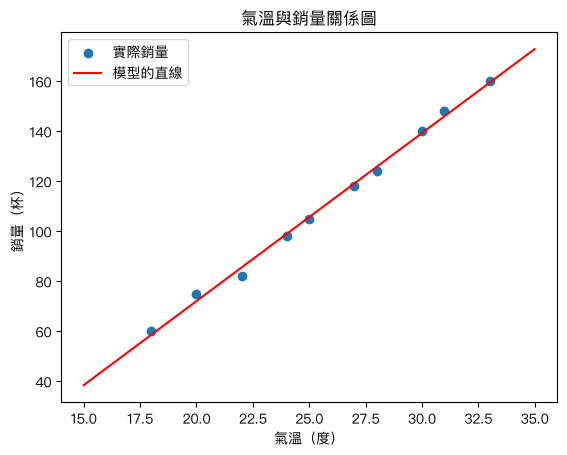

In [25]:
# 練習三：在這裡寫你的程式
temp_line = pd.DataFrame({"氣溫": [15, 35]})
plt.scatter(drink["氣溫"], drink["銷量"], label="實際銷量")
plt.plot(temp_line["氣溫"], drink_model.predict(temp_line), color="red", label="模型的直線")
plt.title("氣溫與銷量關係圖")
plt.xlabel("氣溫（度）")
plt.ylabel("銷量（杯）")
plt.legend()
plt.show

In [ ]:
# 練習三 參考解答
temp_line = pd.DataFrame({"氣溫": [15, 35]})

plt.scatter(drink["氣溫"], drink["銷量"], label="實際銷量")
plt.plot(temp_line["氣溫"], drink_model.predict(temp_line), color="red", label="模型的直線")
plt.title("氣溫與冰飲銷量")
plt.xlabel("氣溫（度）")
plt.ylabel("銷量（杯）")
plt.legend()
plt.show()

### 練習四（挑戰題）：異常值實驗
在 `drink` 資料中加入一筆打錯的資料：**氣溫 20 度、銷量 400 杯**。
重新訓練，比較加入前後的斜率，並把兩條線畫在同一張圖上。

原本斜率： [6.72]
異常斜率： [-0.3]


<function matplotlib.pyplot.show(close=None, block=None)>

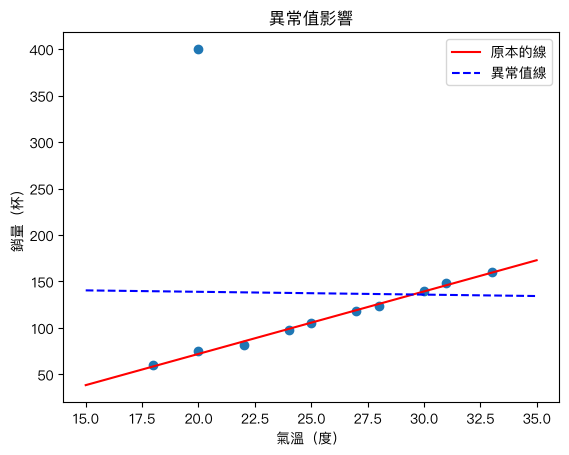

In [31]:
# 練習四：在這裡寫你的程式
drink_bad = pd.concat([drink, pd.DataFrame({"氣溫": [20], "銷量": [400]})], ignore_index = True)

bad = LinearRegression()
bad.fit(drink_bad[["氣溫"]], drink_bad["銷量"])
print("原本斜率：", drink_model.coef_.round(2))
print("異常斜率：", bad.coef_.round(2))

plt.scatter(drink_bad["氣溫"], drink_bad["銷量"])
plt.plot(temp_line["氣溫"], drink_model.predict(temp_line), color="red", label="原本的線")
plt.plot(temp_line["氣溫"], bad.predict(temp_line), color="blue", linestyle="--", label= "異常值線")
plt.title("異常值影響")
plt.legend()
plt.xlabel("氣溫（度）")
plt.ylabel("銷量（杯）")
plt.show

原本的斜率： [6.72]
加入異常值後： [-0.3]


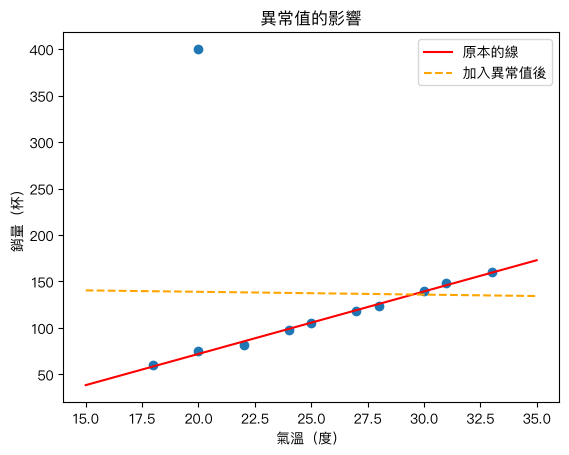

In [28]:
# 練習四 參考解答
drink_bad = pd.concat([drink, pd.DataFrame({"氣溫": [20], "銷量": [400]})], ignore_index=True)

bad = LinearRegression()
bad.fit(drink_bad[["氣溫"]], drink_bad["銷量"])

print("原本的斜率：", drink_model.coef_.round(2))
print("加入異常值後：", bad.coef_.round(2))

plt.scatter(drink_bad["氣溫"], drink_bad["銷量"])
plt.plot(temp_line["氣溫"], drink_model.predict(temp_line), color="red", label="原本的線")
plt.plot(temp_line["氣溫"], bad.predict(temp_line), color="orange", linestyle="--", label="加入異常值後")
plt.title("異常值的影響")
plt.xlabel("氣溫（度）")
plt.ylabel("銷量（杯）")
plt.legend()
plt.show()
# 一個在低溫處的超高銷量，把線的左邊往上拉，斜率變小甚至變成負的，「天氣越熱賣越多」的規律就被破壞了。

---
## 六、小考驗收

先不看筆記回答下面的問題，能回答出來再回到對話中做第 9 堂小考。

1. 線性迴歸的模型，訓練後學到的是哪兩種數字？
2. 斜率是 −8 代表什麼意思？
3. `coef_` 和 `intercept_` 後面為什麼有底線？
4. 斜率 30、截距 50，x = 4 時預測值是多少？
5. 殘差怎麼算？殘差是負數代表點在直線的上面還是下面？
6. 最小平方法為什麼要「平方」，不直接把殘差加起來？
7. `predict()` 和 `score()` 各會得到什麼？
8. 房價模型的截距是 162，可以解讀成「0 坪的房子值 162 萬」嗎？為什麼？

<details>
<summary>點我看參考答案</summary>

1. 斜率（`coef_`）和截距（`intercept_`）。
2. x 每增加 1，y 減少 8（往右下的線）。
3. sklearn 的慣例：訓練後才產生的東西加底線，沒 `fit()` 之前不存在。
4. 30 × 4 + 50 = 170。
5. 實際值 − 預測值。負數代表實際值比預測小 → 點在直線**下面**。
6. 殘差有正有負，直接加會互相抵銷；平方後都變正數，而且大誤差會被懲罰得更重。
7. `predict()` 得到每一題的預測值（一串答案）；`score()` 得到一個分數。
8. 不行。資料裡沒有 0 坪的房子，這是外推；截距只是讓直線在資料範圍內最貼合的數字。

</details>

### 下一堂預告：第 10 堂 分類模型
線性迴歸預測的是**數字**（迴歸）。如果要預測的是**類別**，例如「這封信是不是垃圾郵件」「這位客戶會不會流失」，就要用**分類模型**（第 2 堂學過分類和迴歸的差別）。
第 10 堂會介紹兩個最容易理解的分類模型：**KNN（物以類聚）** 和 **決策樹（一連串的是非題）**。